In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#dataset Loading
df = pd.read_csv("/content/HHS_Unaccompanied_Alien_Children_Program.csv")

In [3]:
#First five rows
df.head()


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


In [4]:
# Last Five rows
df.tail()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN
1169,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#shape
df.shape

(1170, 6)

In [6]:
#Columns
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    object 
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), object(2)
memory usage: 55.0+ KB


In [8]:
#Statistical summary
df.describe()

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children discharged from HHS Care
count,720.000000,720.000000,720.000000,720.000000
mean,93.523611,171.494444,128.668056,173.406944
std,72.646625,126.354965,97.322012,125.702841
min,0.000000,7.000000,0.000000,0.000000
25%,12.000000,36.000000,14.000000,19.750000
50%,99.000000,193.000000,157.000000,181.000000
75%,147.250000,263.250000,199.250000,267.000000
max,333.000000,531.000000,440.000000,505.000000


In [ ]:
#Check Missing Values
df.isnull().sum()

,0
Date,450
Children apprehended and placed in CBP custody*,450
Children in CBP custody,450
Children transferred out of CBP custody,450
Children in HHS Care,450
Children discharged from HHS Care,450


In [9]:
df.isnull().all(axis=1).sum()

np.int64(450)

In [10]:
df =df.dropna()

In [11]:
df.shape

(720, 6)

In [13]:
df.isnull().sum()

,0
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0


In [14]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

print(df.head())

          Date  Children apprehended and placed in CBP custody*  \
719 2023-01-12                                             33.0   
718 2023-01-22                                             32.0   
717 2023-01-23                                             32.0   
716 2023-01-24                                             47.0   
715 2023-01-25                                             20.0   

     Children in CBP custody  Children transferred out of CBP custody  \
719                     53.0                                     34.0   
718                     49.0                                     39.0   
717                     50.0                                     39.0   
716                     42.0                                     47.0   
715                     22.0                                     41.0   

    Children in HHS Care  Children discharged from HHS Care  
719                6,566                              436.0  
718                7,122          

In [15]:
df.columns.tolist()

['Date',
 'Children apprehended and placed in CBP custody*',
 'Children in CBP custody',
 'Children transferred out of CBP custody',
 'Children in HHS Care',
 'Children discharged from HHS Care']

In [16]:
df['Children in CBP custody'] = pd.to_numeric(df['Children in CBP custody'].astype(str).str.replace(',', ''), errors='coerce')

In [17]:
df['Children in HHS Care'] = pd.to_numeric(df['Children in HHS Care'].astype(str).str.replace(',', ''), errors='coerce')

In [18]:
#Total system load
df['Total Load'] = df['Children in CBP custody'] + df['Children in HHS Care']

In [19]:
print(df[['Date', 'Total Load']].head())

          Date  Total Load
719 2023-01-12      6619.0
718 2023-01-22      7171.0
717 2023-01-23      7330.0
716 2023-01-24      7475.0
715 2023-01-25      7560.0


In [20]:
#Net daily intake Calculation
df['Net Intake'] = df['Children transferred out of CBP custody'] - df['Children discharged from HHS Care']

In [21]:
print(df[['Date', 'Net Intake']].head())

          Date  Net Intake
719 2023-01-12      -402.0
718 2023-01-22      -188.0
717 2023-01-23      -142.0
716 2023-01-24      -128.0
715 2023-01-25      -139.0


In [22]:
#growth Rate Calculation
df['Growth Rate'] = df['Total Load'].pct_change() * 100

In [23]:
print(df[['Date', 'Total Load', 'Growth Rate']].head(10))

          Date  Total Load  Growth Rate
719 2023-01-12      6619.0          NaN
718 2023-01-22      7171.0     8.339628
717 2023-01-23      7330.0     2.217264
716 2023-01-24      7475.0     1.978172
715 2023-01-25      7560.0     1.137124
714 2023-01-29      7517.0    -0.568783
713 2023-01-30      7797.0     3.724890
712 2023-01-31      7839.0     0.538669
711 2023-02-01      7935.0     1.224646
710 2023-02-02      7892.0    -0.541903


In [24]:
#Day Average
df['7 Day Average'] = df['Total Load'].rolling(7).mean()

In [25]:
print(df[['Date', 'Total Load', '7 Day Average']].tail(10))

        Date  Total Load  7 Day Average
9 2025-12-08      2467.0    2448.285714
8 2025-12-09      2473.0    2454.000000
7 2025-12-10      2493.0    2462.142857
6 2025-12-11      2484.0    2468.285714
5 2025-12-14      2497.0    2474.857143
4 2025-12-15      2512.0    2482.714286
3 2025-12-16      2522.0    2492.571429
2 2025-12-17      2512.0    2499.000000
1 2025-12-18      2522.0    2506.000000
0 2025-12-21      2502.0    2507.285714


In [26]:
df['14 Day Average'] = df['Total Load'].rolling(14).mean()

In [27]:
print(df[['Date', '14 Day Average']].tail(10))

        Date  14 Day Average
9 2025-12-08     2425.500000
8 2025-12-09     2431.928571
7 2025-12-10     2440.571429
6 2025-12-11     2446.785714
5 2025-12-14     2452.214286
4 2025-12-15     2459.428571
3 2025-12-16     2466.571429
2 2025-12-17     2473.642857
1 2025-12-18     2480.000000
0 2025-12-21     2484.714286


In [28]:
#Backlog Analysis
df['Backlog'] = df['Net Intake'].rolling(7).sum()

In [29]:
print(df[['Date', 'Net Intake', 'Backlog']].tail(10))

        Date  Net Intake  Backlog
9 2025-12-08         5.0      4.0
8 2025-12-09        -1.0     -7.0
7 2025-12-10        -4.0     -6.0
6 2025-12-11        -1.0     -5.0
5 2025-12-14        -4.0    -10.0
4 2025-12-15         2.0     -2.0
3 2025-12-16         6.0      3.0
2 2025-12-17         1.0     -1.0
1 2025-12-18       -10.0    -10.0
0 2025-12-21        -3.0     -9.0


**KPI Calculations**

In [30]:
#Total Children Under Care
print("Total Children Under Care:", df['Total Load'].iloc[-1])

Total Children Under Care: 2502.0


In [31]:
# Avg care load
print("Average Care Load:", df['Total Load'].mean())

Average Care Load: 6232.769444444444


In [32]:
#Maximum care load
print("Maximum Care Load:", df['Total Load'].max())

Maximum Care Load: 11762.0


In [33]:
#Total Net Intake
print("Total Net Intake:", df['Net Intake'].sum())

Total Net Intake: -32212.0


In [34]:
#Care Load Volality
print("Care Load Volatility:", df['Total Load'].diff().std())

Care Load Volatility: 140.27901476269008


**Graphs**

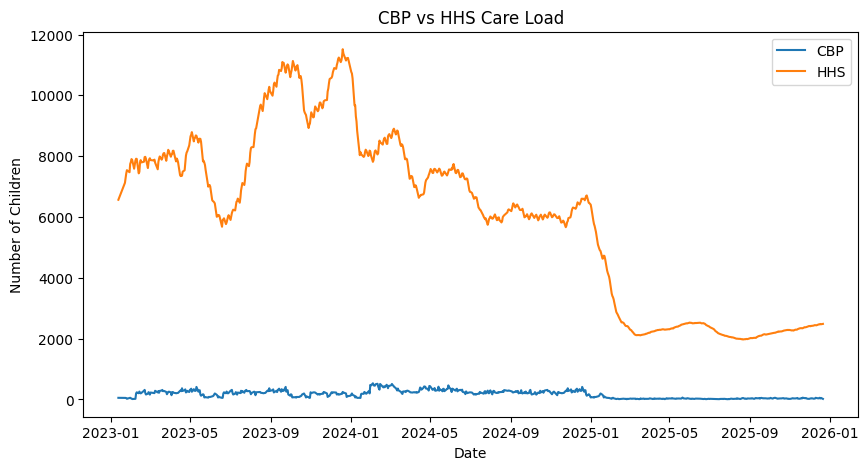

In [35]:
# 1. CBP vs HHS Comparision
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Children in CBP custody'], label='CBP')
plt.plot(df['Date'], df['Children in HHS Care'], label='HHS')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.title('CBP vs HHS Care Load')
plt.legend()
plt.show()

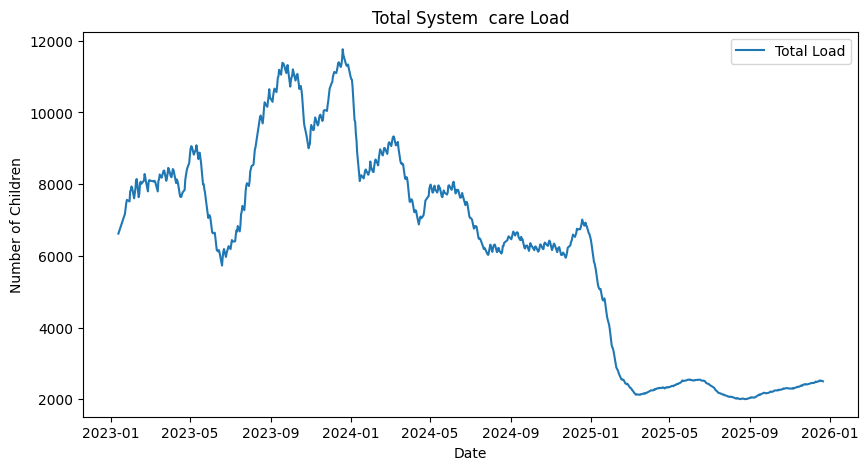

In [36]:
# 2. Total System Load
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Total Load'], label='Total Load')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.title('Total System  care Load')
plt.legend()
plt.show()

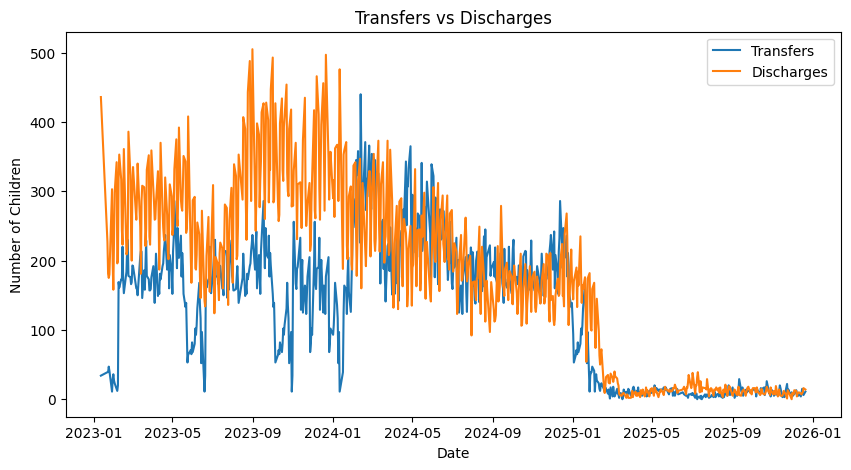

In [37]:
# 3. Transfers vs Discharges
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Children transferred out of CBP custody'], label='Transfers')
plt.plot(df['Date'], df['Children discharged from HHS Care'], label='Discharges')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.title('Transfers vs Discharges')
plt.legend()
plt.show()

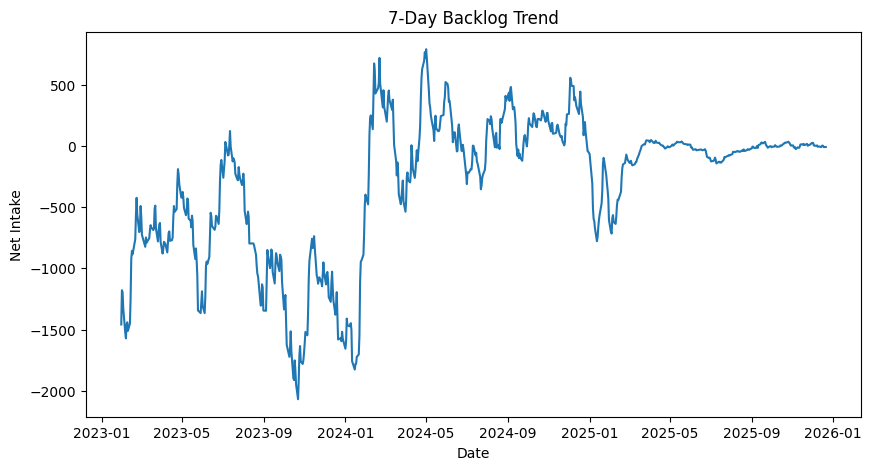

In [38]:
# 4. Backlog Trend Graph
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Backlog'])
plt.xlabel('Date')
plt.ylabel('Net Intake')
plt.title('7-Day Backlog Trend')
plt.show()

In [39]:
#Monthly Analysis
df['Month'] = df['Date'].dt.to_period('M')

In [40]:
monthly_data = df.groupby('Month')['Total Load'].mean()

In [41]:
print(monthly_data)

Month
2023-01     7413.500000
2023-02     7967.105263
2023-03     8190.473684
2023-04     8092.857143
2023-05     8404.090909
2023-06     6282.100000
2023-07     7073.380952
2023-08     9585.100000
2023-09    10992.368421
2023-10    10308.227273
2023-11     9909.600000
2023-12    11255.263158
2024-01     9021.636364
2024-02     8766.800000
2024-03     8703.857143
2024-04     7336.318182
2024-05     7836.047619
2024-06     7691.476190
2024-07     6498.761905
2024-08     6258.736842
2024-09     6452.636364
2024-10     6276.285714
2024-11     6151.421053
2024-12     6690.409091
2025-01     5080.045455
2025-02     2804.210526
2025-03     2185.909091
2025-04     2298.000000
2025-05     2439.777778
2025-06     2511.470588
2025-07     2201.142857
2025-08     2026.900000
2025-09     2118.045455
2025-10     2265.380952
2025-11     2360.684211
2025-12     2481.466667
Freq: M, Name: Total Load, dtype: float64


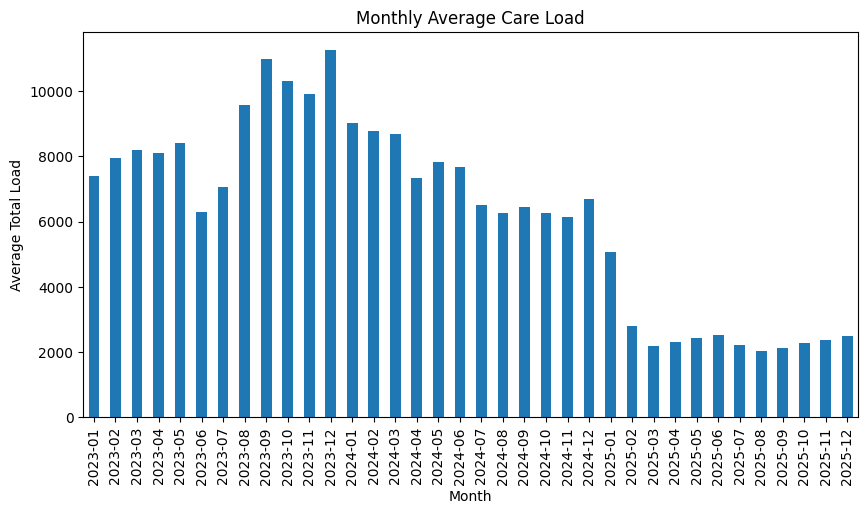

In [42]:
# 4.Monthly Trend Graph
monthly_data.plot(kind='bar', figsize=(10,5))
plt.title('Monthly Average Care Load')
plt.xlabel('Month')
plt.ylabel('Average Total Load')
plt.show()

**Weekly Analysis**

In [43]:
df['Week'] = df['Date'].dt.to_period('W')

In [44]:
weekly_data = df.groupby('Week')['Total Load'].mean()

In [45]:
print(weekly_data)

Week
2023-01-09/2023-01-15    6619.00
2023-01-16/2023-01-22    7171.00
2023-01-23/2023-01-29    7470.50
2023-01-30/2023-02-05    7813.40
2023-02-06/2023-02-12    7901.40
                          ...   
2025-11-17/2025-11-23    2390.20
2025-11-24/2025-11-30    2419.75
2025-12-01/2025-12-07    2447.60
2025-12-08/2025-12-14    2482.80
2025-12-15/2025-12-21    2514.00
Freq: W-SUN, Name: Total Load, Length: 154, dtype: float64


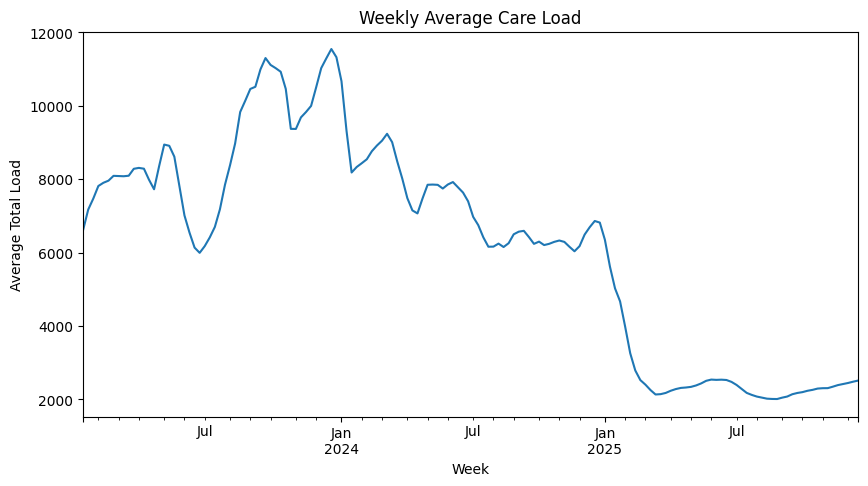

In [46]:
#5. Weekly Graph
weekly_data.plot(kind='line', figsize=(10,5))
plt.title('Weekly Average Care Load')
plt.xlabel('Week')
plt.ylabel('Average Total Load')
plt.show()

In [47]:
#Saved Cleaned Dataset
df.to_csv('UAC_Cleaned_Data.csv', index=False)

In [48]:
from google.colab import files
files.download('UAC_Cleaned_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
#Early vs Late Period Comparison
mid = df['Date'].median()


In [50]:
print("Early Period Average:", df[df['Date'] <= mid]['Total Load'].mean())
print("Late Period Average:", df[df['Date'] > mid]['Total Load'].mean())

Early Period Average: 8610.844444444445
Late Period Average: 3854.6944444444443


**Data Validation**

In [51]:
# Duplicates dates Check
print(df['Date'].duplicated().sum())


0


In [52]:
# Transfers Validation
print((df['Children transferred out of CBP custody'] > df['Children in CBP custody']).sum())


86


In [53]:
print((df['Children discharged from HHS Care'] > df['Children in HHS Care']).sum())


0


In [54]:
#Missing Values Check
print(df.isnull().sum())

Date                                                0
Children apprehended and placed in CBP custody*     0
Children in CBP custody                             0
Children transferred out of CBP custody             0
Children in HHS Care                                0
Children discharged from HHS Care                   0
Total Load                                          0
Net Intake                                          0
Growth Rate                                         1
7 Day Average                                       6
14 Day Average                                     13
Backlog                                             6
Month                                               0
Week                                                0
dtype: int64


In [55]:
display(df[df['Children transferred out of CBP custody'] > df['Children in CBP custody']].head(10))

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total Load,Net Intake,Growth Rate,7 Day Average,14 Day Average,Backlog,Month,Week
716,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,1.978172,NaN,NaN,NaN,2023-01,2023-01-23/2023-01-29
715,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,1.137124,NaN,NaN,NaN,2023-01,2023-01-23/2023-01-29
710,2023-02-02,15.0,13.0,23.0,7879,298.0,7892.0,-275.0,-0.541903,7716.428571,NaN,-1327.0,2023-02,2023-01-30/2023-02-05
697,2023-02-22,107.0,215.0,230.0,7978,232.0,8193.0,-2.0,-1.062674,8058.714286,7958.142857,-424.0,2023-02,2023-02-20/2023-02-26
696,2023-02-23,101.0,162.0,178.0,7914,386.0,8076.0,-208.0,-1.428048,8106.428571,7971.285714,-560.0,2023-02,2023-02-20/2023-02-26
692,2023-03-01,84.0,158.0,193.0,7930,307.0,8088.0,-114.0,-0.295858,8084.000000,8021.714286,-580.0,2023-03,2023-02-27/2023-03-05
672,2023-04-03,118.0,139.0,168.0,8054,284.0,8193.0,-116.0,-0.243516,8259.857143,8265.714286,-842.0,2023-04,2023-04-03/2023-04-09
656,2023-04-25,81.0,230.0,242.0,8017,202.0,8247.0,40.0,1.489048,7856.428571,7958.714286,-190.0,2023-04,2023-04-24/2023-04-30
649,2023-05-04,153.0,253.0,286.0,8790,332.0,9043.0,-46.0,-0.154577,8755.142857,8305.785714,-506.0,2023-05,2023-05-01/2023-05-07
640,2023-05-17,57.0,162.0,193.0,8569,307.0,8731.0,-114.0,-1.633619,8876.857143,8879.928571,-612.0,2023-05,2023-05-15/2023-05-21


In [57]:
#Capacity Stress analysis
print("Maximum Care Load:", df['Total Load'].max())
print("Average Care Load:", df['Total Load'].mean())

Maximum Care Load: 11762.0
Average Care Load: 6232.769444444444


In [58]:
#High load days analysis
threshold = df['Total Load'].quantile(0.90)
print("High Load Threshold:", threshold)
display(df[df['Total Load'] >= threshold][['Date', 'Total Load']].head(10))

High Load Threshold: 9920.9


,Date,Total Load
577,2023-08-22,10130.0
576,2023-08-23,10283.0
575,2023-08-24,10240.0
574,2023-08-27,10156.0
573,2023-08-28,10309.0
572,2023-08-29,10452.0
571,2023-08-30,10647.0
570,2023-08-31,10420.0
569,2023-09-04,10294.0
568,2023-09-05,10472.0


In [59]:
#Missing dates check
print("Missing Dates:", pd.date_range(df['Date'].min(), df['Date'].max(), freq='D').difference(df['Date']).size)

Missing Dates: 355


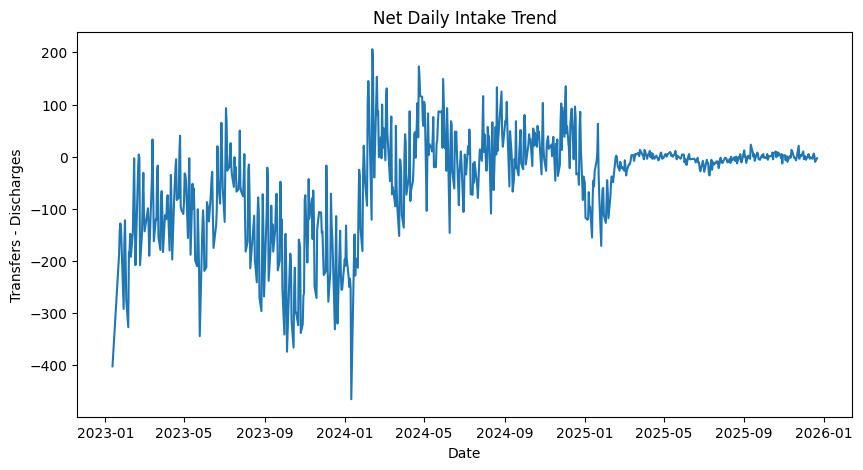

In [60]:
#Net Intake Trend Graph
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Net Intake'])
plt.title('Net Daily Intake Trend')
plt.xlabel('Date')
plt.ylabel('Transfers - Discharges')
plt.show()

In [61]:
#Final Analysis Summary
print("Total Records:", len(df))
print("Date Range:", df['Date'].min(), "to", df['Date'].max())
print("Average Total Load:", round(df['Total Load'].mean(), 2))
print("Maximum Total Load:", df['Total Load'].max())
print("Average Net Intake:", round(df['Net Intake'].mean(), 2))

Total Records: 720
Date Range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00
Average Total Load: 6232.77
Maximum Total Load: 11762.0
Average Net Intake: -44.74


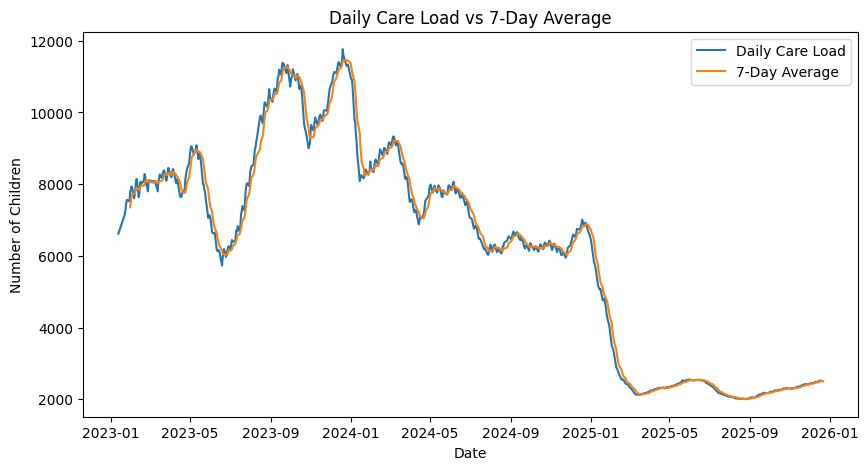

In [62]:
#Total Care Load vs 7 day average
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Total Load'], label='Daily Care Load')
plt.plot(df['Date'], df['7 Day Average'], label='7-Day Average')
plt.title('Daily Care Load vs 7-Day Average')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.legend()
plt.show()

**Final Dataset save,Download**

In [63]:
#Dataset save
df.to_csv('UAC_Final_Cleaned_Data.csv', index=False)


In [64]:
#Download Dataset
from google.colab import files
files.download('UAC_Final_Cleaned_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>